In [1]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from vol_surface.deribit import get_book_summary_by_currency

print(len(get_book_summary_by_currency("BTC", "option")))

966


In [3]:
def build_surface_arrays(currency="BTC", min_iv=1.0):
    """Ritorna 3 array allineati: maturity (anni), moneyness (K/F), IV (decimale)."""
    data = get_book_summary_by_currency(currency, "option")
    now = datetime.now(timezone.utc)

    maturity, moneyness, iv = [], [], []
    for d in data:
        mark_iv = d.get("mark_iv")
        F = d.get("underlying_price")
        if not mark_iv or mark_iv < min_iv or not F:
            continue

        # es. BTC-28NOV26-100000-C
        _, exp_str, strike_str, cp = d["instrument_name"].split("-")
        K = float(strike_str)

        # solo OTM: call se K >= F, put se K < F
        if (cp == "C" and K < F) or (cp == "P" and K >= F):
            continue

        # scadenza Deribit: 08:00 UTC
        expiry = datetime.strptime(exp_str, "%d%b%y").replace(hour=8, tzinfo=timezone.utc)
        T = (expiry - now).total_seconds() / (365 * 24 * 3600)
        if T <= 0:
            continue

        maturity.append(T)
        moneyness.append(K / F)
        iv.append(mark_iv / 100)

    return np.array(maturity), np.array(moneyness), np.array(iv)


T, M, IV = build_surface_arrays("BTC")
print(len(T), T[:5], M[:5], IV[:5])

483 [0.3993429  0.15002783 0.00208263 0.24591824 0.64865797] [1.31430107 2.17743815 0.97501394 1.14681617 0.81024771] [0.3812 0.6826 0.3206 0.3689 0.4224]


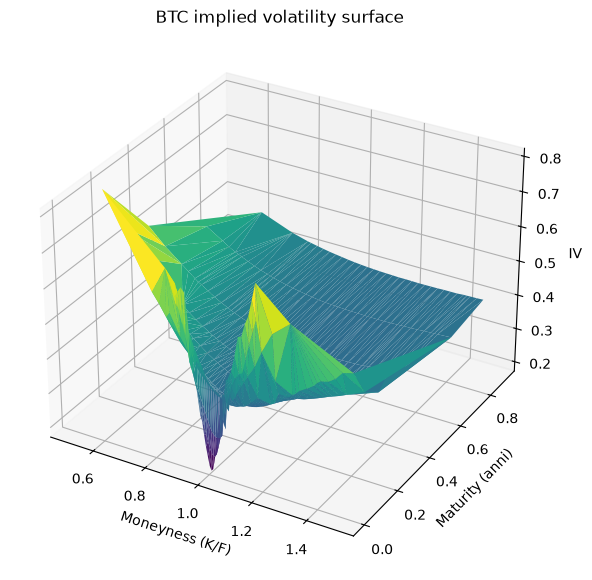

In [4]:
mask = (M > 0.5) & (M < 1.5)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_trisurf(M[mask], T[mask], IV[mask], cmap="viridis")
ax.set_xlabel("Moneyness (K/F)")
ax.set_ylabel("Maturity (anni)")
ax.set_zlabel("IV")
ax.set_title("BTC implied volatility surface")
plt.show()